In [1]:
from tbparse import SummaryReader
import matplotlib.pyplot as plt
import seaborn as sns
import pathlib
import glob 
import scienceplots

print("Current working directory:", pathlib.Path.cwd().parent.parent)

source_dir = pathlib.Path.cwd().parent.parent
print("Source directory:", source_dir)
# make a list of all events in the log file
from pathlib import Path
source_dir = str(source_dir)

source_dir = source_dir + "/scripts/skrl/logs/skrl/DR_9600_10/"
print("Source directory with logs:", source_dir)

sns.set_style("whitegrid")  # Choose your style
# sns.set_context("paper", font_scale=1.5)
plt.style.use(['science', 'ieee'])
# plt.rcParams.update({'font.size': 20})
# sns.set_style("whitegrid")  # Choose your style
# sns.set_context("paper")    
# sns.color_palette("colorblind")
# collect all dirs
paths = sorted(glob.glob(source_dir + "/*/events*"))
print(paths)

Current working directory: /home/vikas-admin/Codebases/SPEAR/MetaRL/QuadControl
Source directory: /home/vikas-admin/Codebases/SPEAR/MetaRL/QuadControl
Source directory with logs: /home/vikas-admin/Codebases/SPEAR/MetaRL/QuadControl/scripts/skrl/logs/skrl/DR_9600_10/
[]


With tensorboard dataframes

In [2]:
import glob

log_dir = f"../logs/skrl/baseline/*/events.out.*"
paths = sorted(glob.glob(source_dir))
paths

['/home/vikas-admin/Codebases/SPEAR/MetaRL/QuadControl/scripts/skrl/logs/skrl/DR_9600_10/']

In [3]:
tasks = ["hover", 
         "straight", 
         "circle", 
         "lemniscate", 
        #  "slalom"
         ]

In [4]:
from tensorboard.backend.event_processing import event_accumulator
import pandas as pd
import os

def extract_scalars(log_dir, algorithm, task, run_id):
    ea = event_accumulator.EventAccumulator(log_dir)
    ea.Reload()
    data = []
    for tag in ea.Tags()["scalars"]:
        for s in ea.Scalars(tag):
            data.append({
                "step": s.step,
                "value": s.value,
                "tag": tag,
                "algorithm": algorithm,
                "task": task,
                "run": run_id
            })
    return pd.DataFrame(data)

# Aggregate all logs
base_dir = source_dir
all_dfs = []
for algorithm in ["baseline", "randomised"]:
    for task in tasks:
        task= f"DR_{task}"
        # if algorithm=="randomised":
            # task=f"{task}_rand"
        task_dir = os.path.join(base_dir, algorithm, task)
        for run in os.listdir(task_dir):
            log_path = os.path.join(task_dir, run)
            df = extract_scalars(log_path, algorithm, task, run)
            all_dfs.append(df)

full_df = pd.concat(all_dfs)


In [258]:
summary = (
    full_df.query("tag == 'Reward / Total reward (mean)'")
)
summary.head()

,step,value,tag,algorithm,task,run
500,96,-5.611258,Reward / Total reward (mean),baseline,DR_hover,hover_ppo_torch_2026-01-13_10-58-39
501,192,-1.823916,Reward / Total reward (mean),baseline,DR_hover,hover_ppo_torch_2026-01-13_10-58-39
502,288,-0.249964,Reward / Total reward (mean),baseline,DR_hover,hover_ppo_torch_2026-01-13_10-58-39
503,384,0.198207,Reward / Total reward (mean),baseline,DR_hover,hover_ppo_torch_2026-01-13_10-58-39
504,480,0.484898,Reward / Total reward (mean),baseline,DR_hover,hover_ppo_torch_2026-01-13_10-58-39


Original labels: ['baseline', 'randomised']


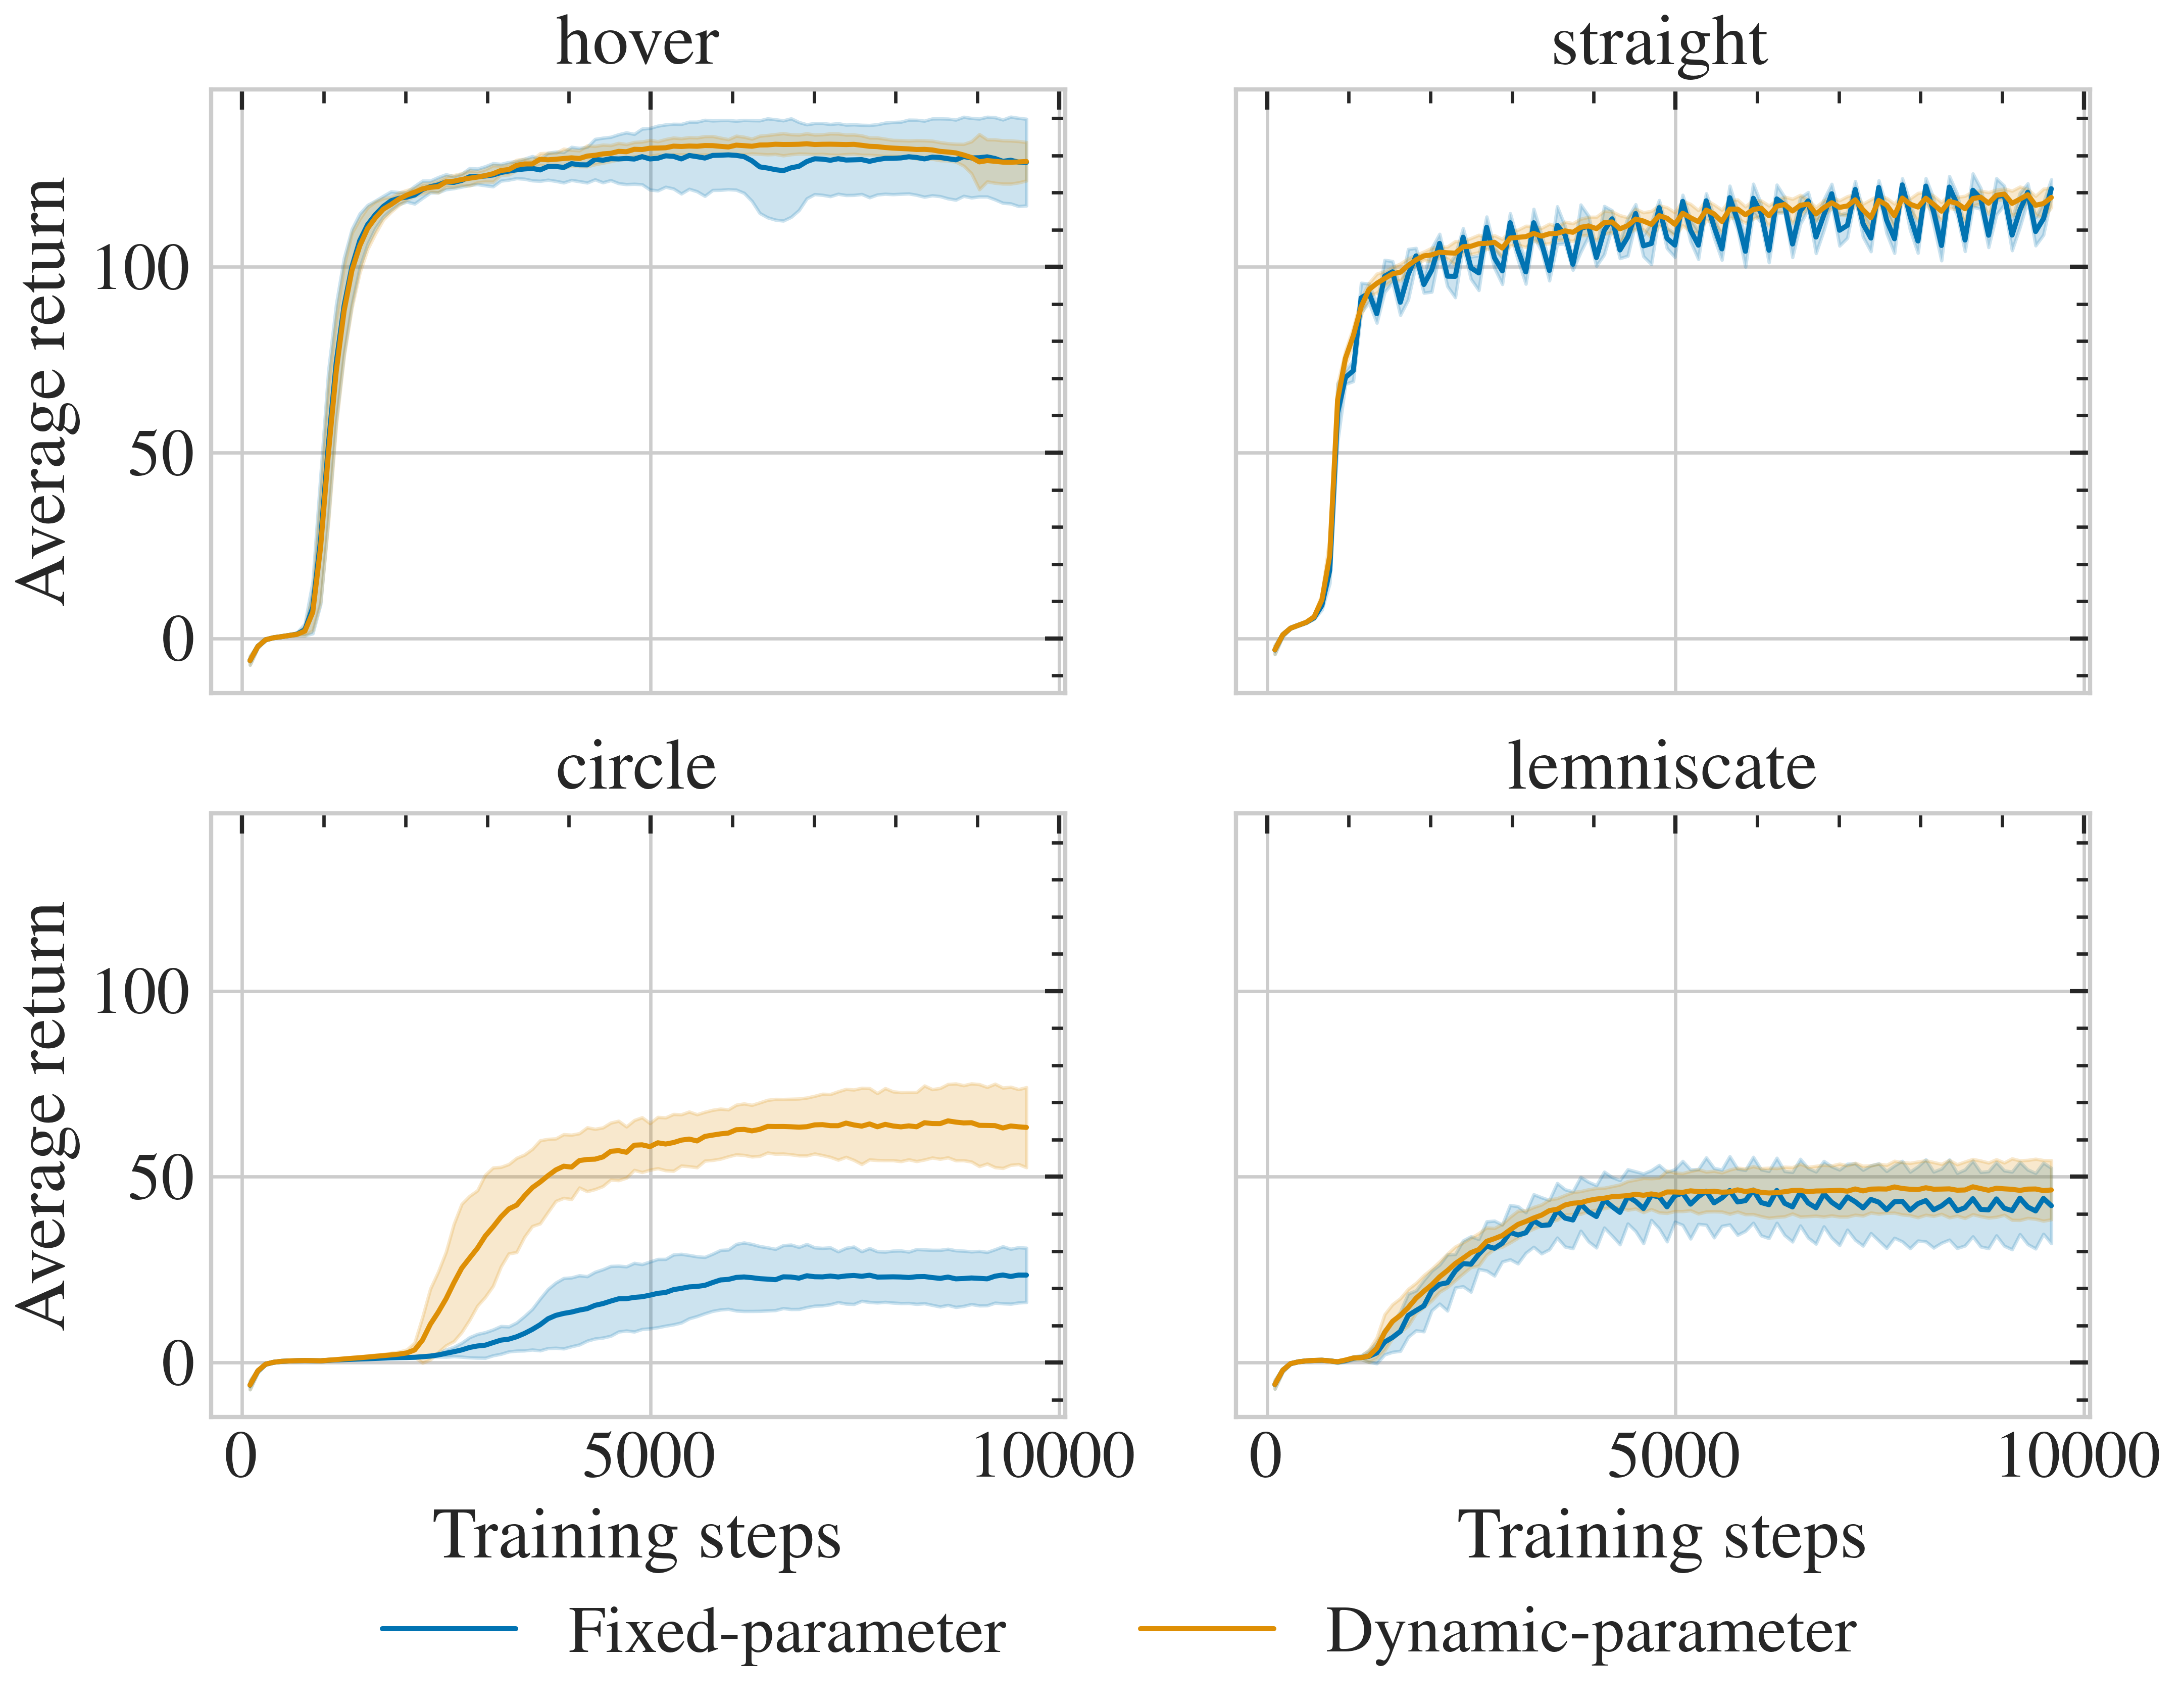

In [259]:
import seaborn as sns
import matplotlib.pyplot as plt

# textwidth_in = 5.8
# fig_width = 0.48 * textwidth_in
# fig_height = 0.75 * fig_width

# plt.rcParams.update({
#     "text.usetex": True,
#     "font.size": 25,
#     # "font.family": "lmodern",
#     "figure.figsize": (fig_width, fig_height),
# })

sns.set_context("paper", font_scale=1.8)

fig, axes = plt.subplots(2, len(tasks)//2, figsize=(4 * 2, 3 * 2), sharey=True, sharex=True,)
axes = axes.flatten()
# plt.xlabel("Step")
# plt.ylabel("Total Reward")
plt.rcParams.update({
    # "text.usetex": True,
    "font.size": 25,
    # "font.family": "lmodern",
    # "figure.figsize": (fig_width, fig_height),
})

# sns.set(font_scale=1.5)
for i, t in enumerate(tasks):
    # plt.figure(figsize=(5, 4))
    axes[i] = sns.lineplot(
        data=summary[summary["task"] == f"DR_{t}"],
        x="step", y="value",
        hue="algorithm",
        errorbar="sd",
        ax=axes[i],
        palette="colorblind"

    )
    # plt.title(f"Reward Comparison for {t} Task")
    # axes[i].xlabel("Step")
    # plt.ylabel("Total reward")sampling
    axes[i].set_xlabel("Training steps")
    axes[i].set_ylabel("Average return")
    axes[i].set_title(f"{t}")
    axes[i].legend_.remove()
    # plt.savefig(f"reward_comparison_{t}.pdf", dpi=300)
    # plt.show()
# zoom in on certain region

# rename legend labels
new_labels = ['Fixed-parameter', 'Dynamic-parameter']

handles, labels = axes[0].get_legend_handles_labels()
print("Original labels:", labels)
labels = new_labels
# loc = southeast
# legend on southeast

# loc = 
fig.legend(handles, labels, 
           loc="lower center", 
           bbox_to_anchor=(0.5, -0.02),
           ncol=2,)
plt.subplots_adjust(bottom=0.15)
# plt.title("Aggregate Reward Comparison Across Tasks")
plt.savefig("log_figures/task_reward_comparison_base_rand_25.pdf", dpi=300)


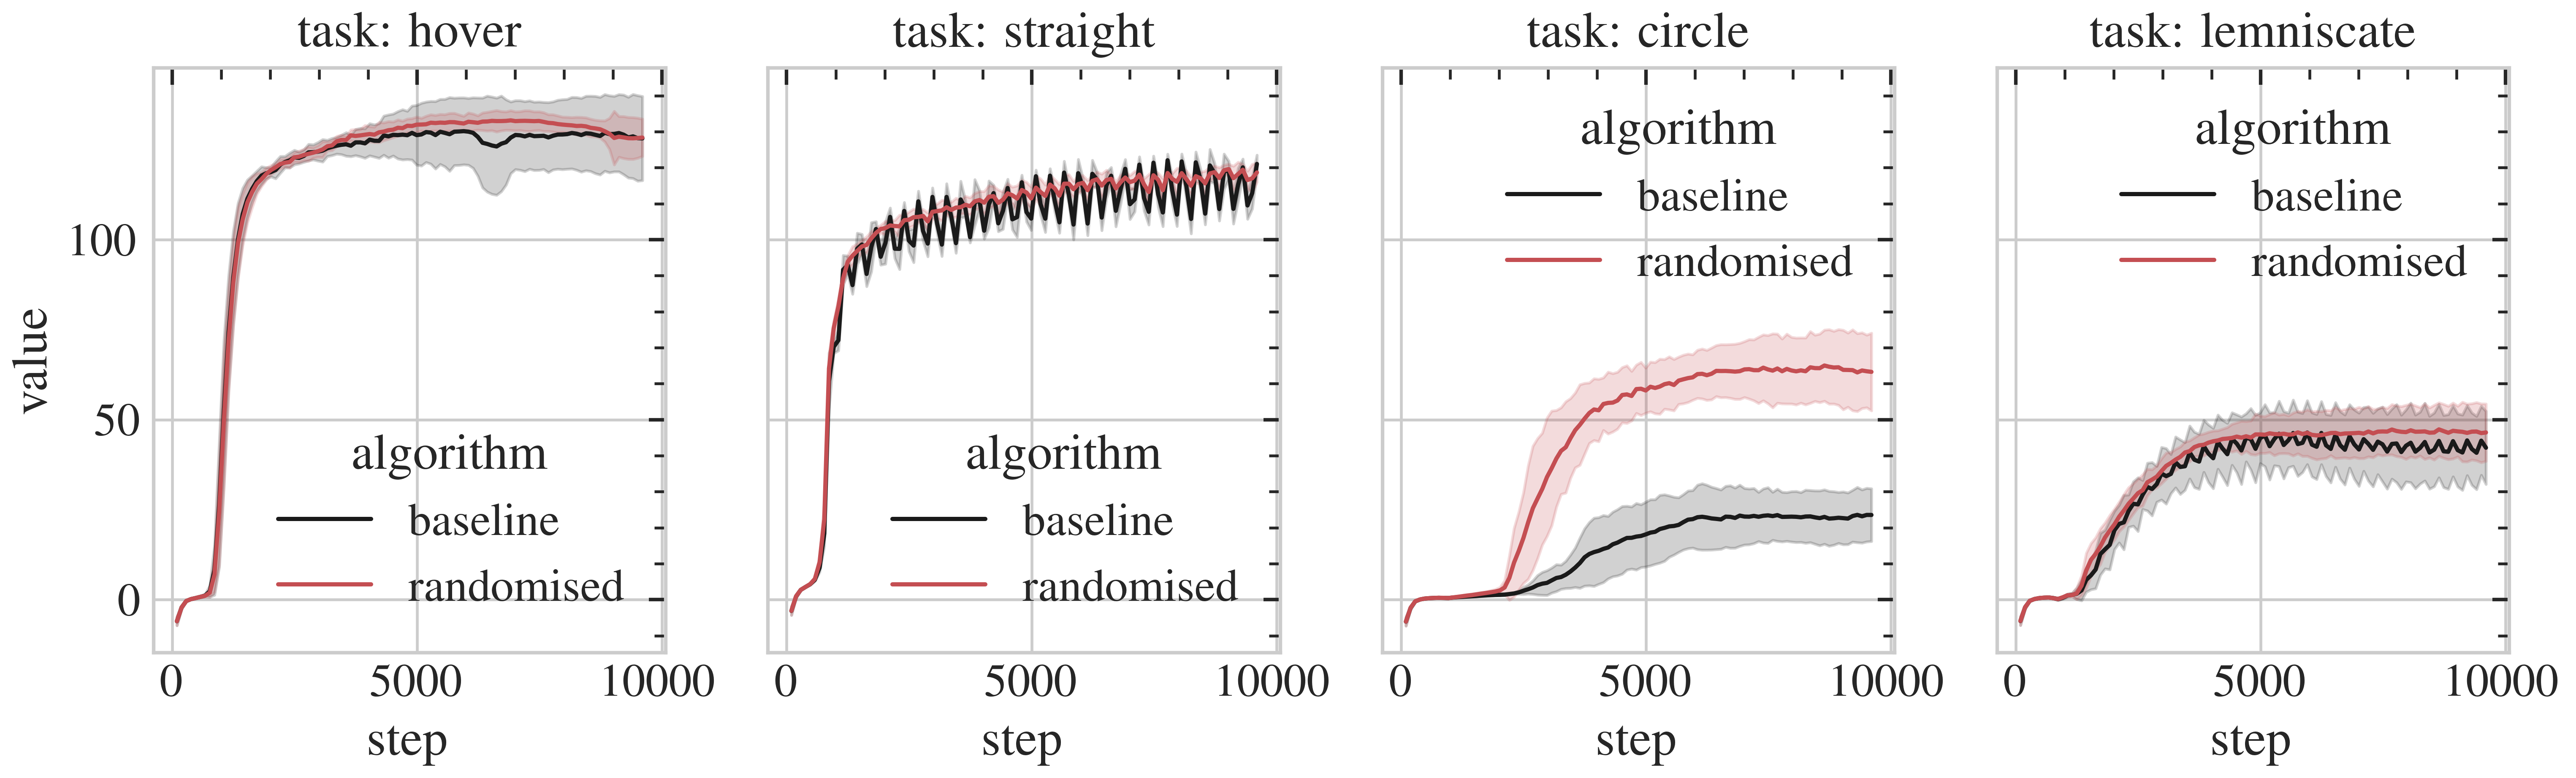

In [260]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_context("paper", font_scale=1.5)
plt.rcParams.update({'font.size': 18})
fig, axes = plt.subplots(1, len(tasks), figsize=(12, 3), sharey=True, sharex=True)
# axes = axes.flatten()
# fig.fontsize = 50
for i, t in enumerate(tasks):
    # plt.figure(figsize=(5, 4))
    axes[i] = sns.lineplot(
        data=summary[summary["task"] == f"DR_{t}"],
        x="step", y="value",
        hue="algorithm",
        errorbar="sd",
        ax=axes[i]
    )
    # plt.title(f"Reward Comparison for {t} Task")
    # plt.xlabel("Step")
    # plt.ylabel("Average Reward")
    axes[i].set_title(f"task: {t}")
    # axes[i].legend_.remove()
    # plt.savefig(f"reward_comparison_{t}.pdf", dpi=300)
    # plt.show()




handles, labels = axes[0].get_legend_handles_labels()
# fig.legend(handles, labels, loc='best', ncols=1, title="Training type")
# plt.title("Aggregate Reward Comparison Across Tasks")
# plt.savefig("task_reward_comparison_horizontal.pdf", dpi=300,)

# plt.savefig("aggregate_reward_comparison_sep.png", dpi=300)


## Rliable

<Axes: xlabel='task', ylabel='value'>

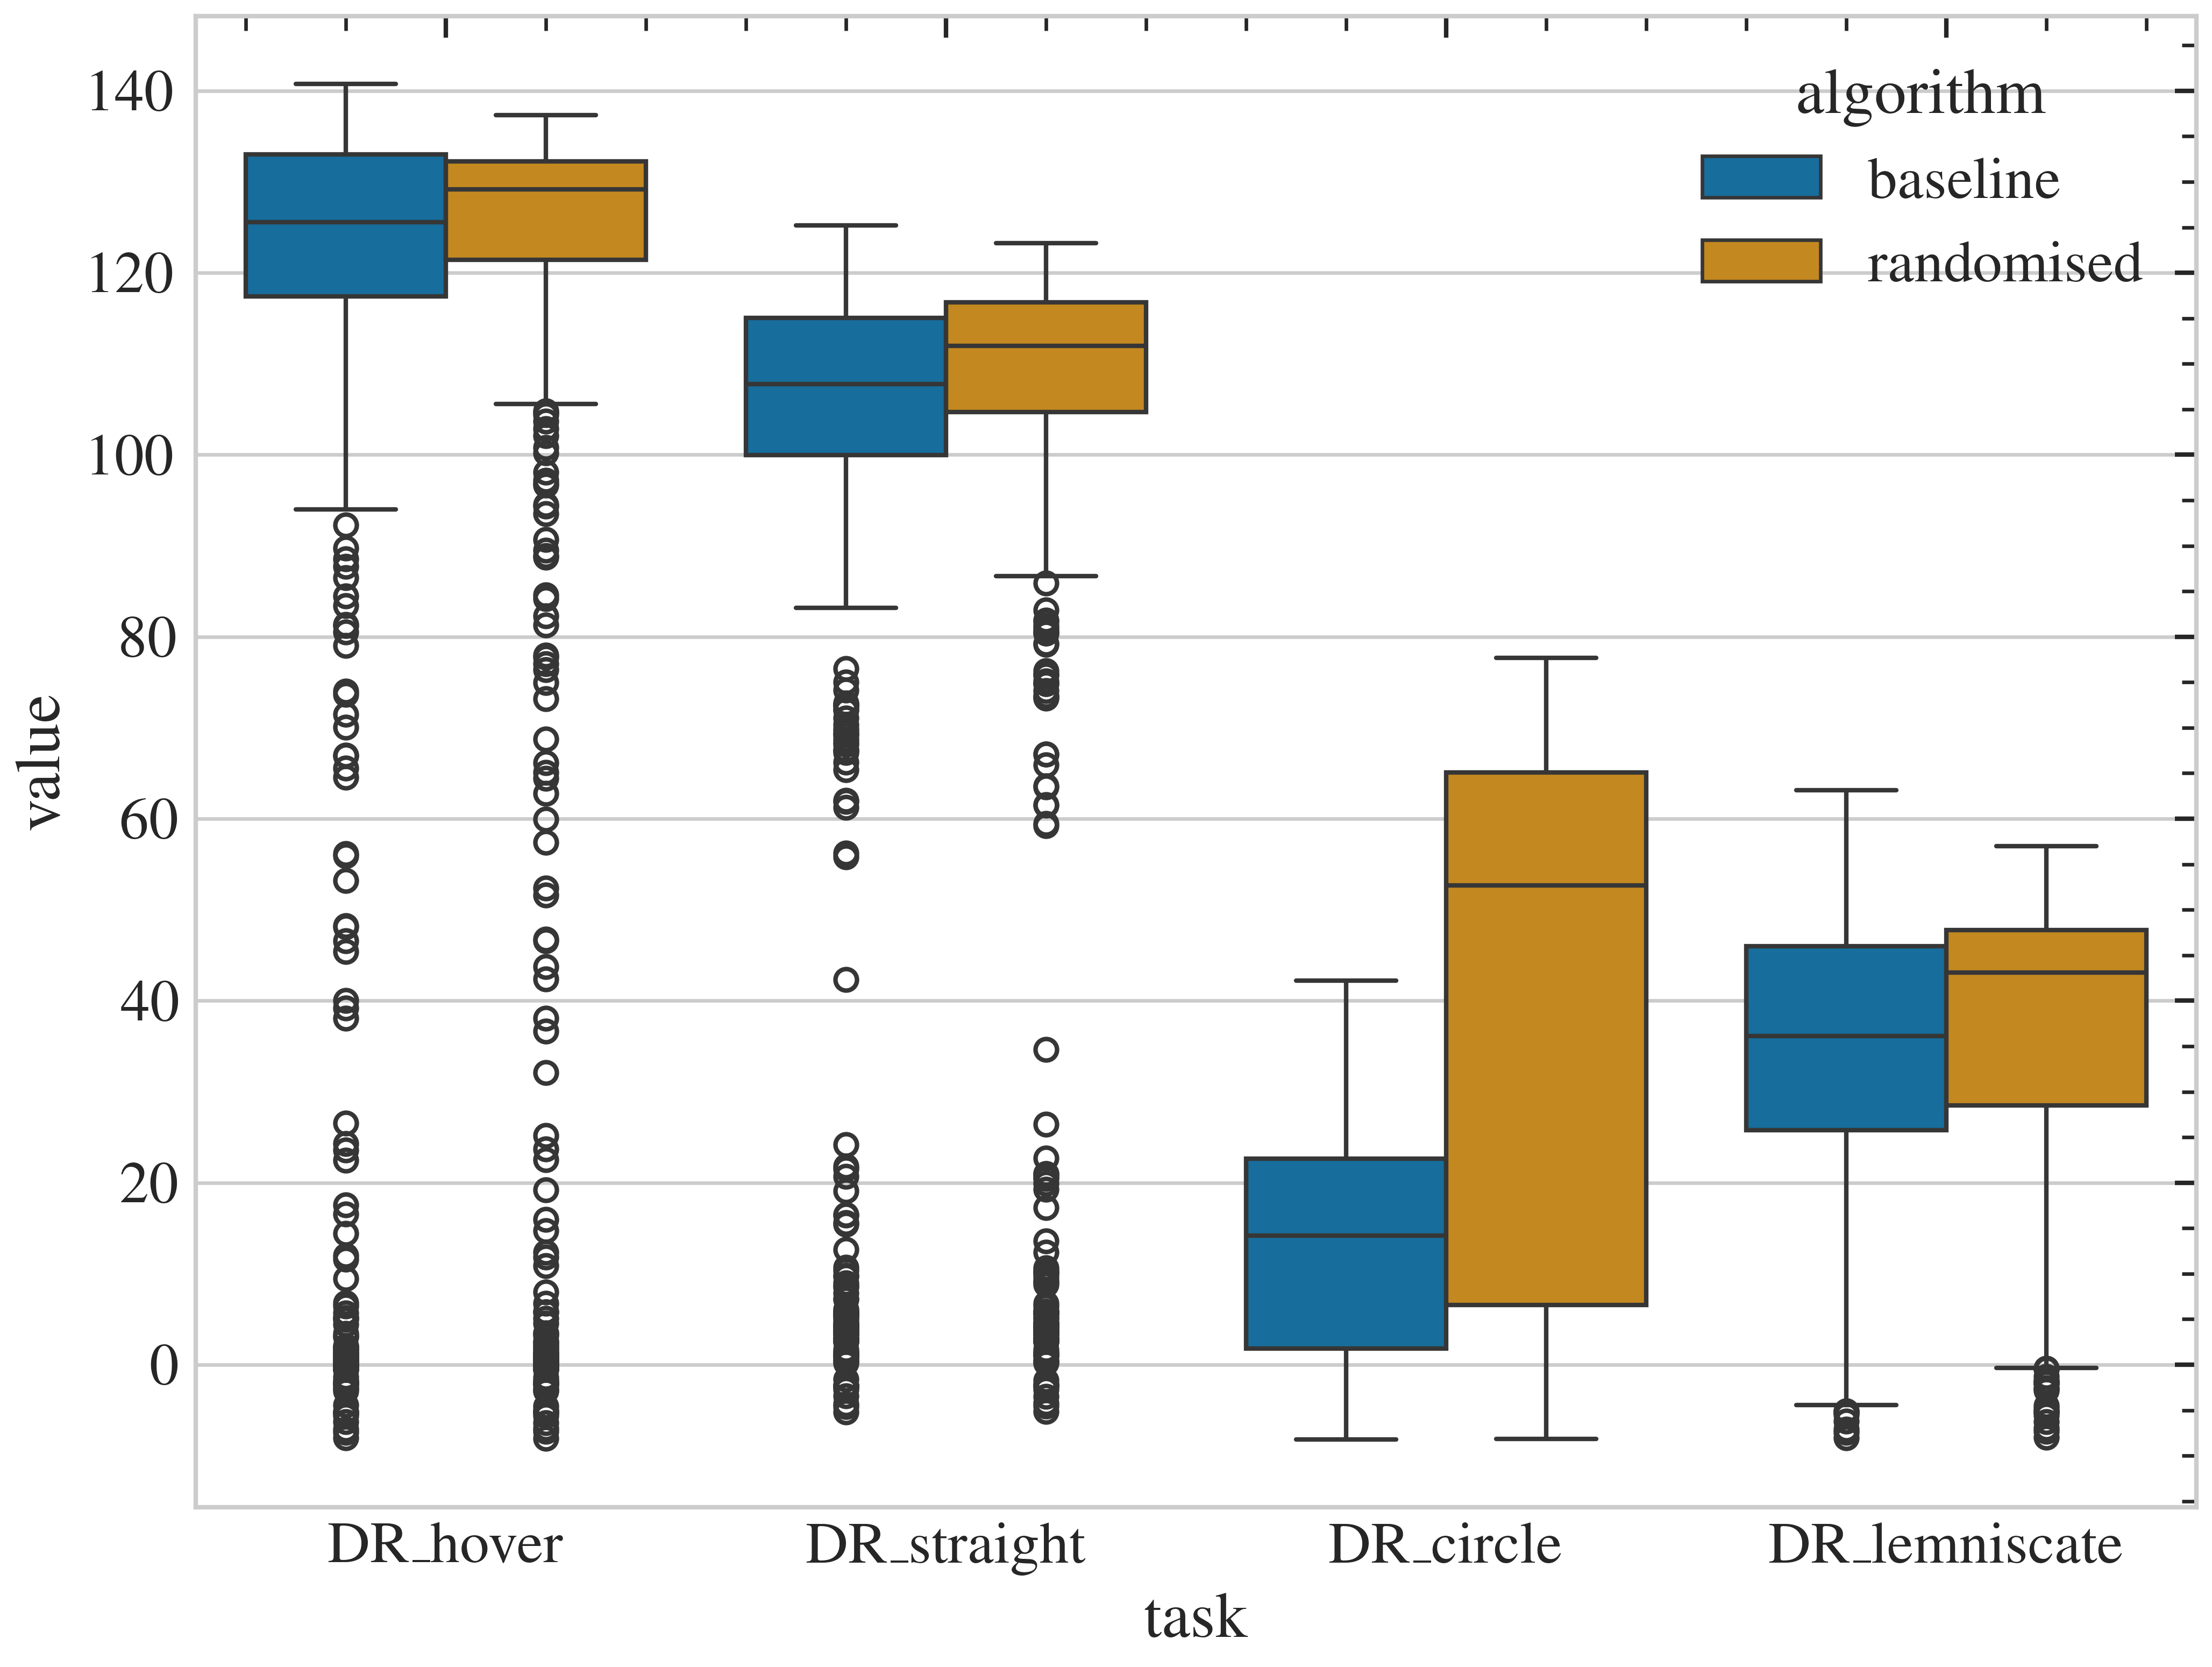

In [261]:
ax,_ = plt.subplots(figsize=(8, 6))
sns.boxplot(
    data=summary,
    x="task",
    y="value",
    hue="algorithm",
    palette="colorblind",
    # figsize=(8, 6)
)

## Reward distribution for each task

In [262]:
full_df['tag'].unique()

array(['Reward / Instantaneous reward (max)',
       'Reward / Instantaneous reward (min)',
       'Reward / Instantaneous reward (mean)',
       'Reward / Total reward (max)', 'Reward / Total reward (min)',
       'Reward / Total reward (mean)', 'Episode / Total timesteps (max)',
       'Episode / Total timesteps (min)',
       'Episode / Total timesteps (mean)',
       'Info / Episode_Reward/lin_vel', 'Info / Episode_Reward/ang_vel',
       'Info / Episode_Reward/distance_to_goal', 'Info / Action/thrust',
       'Info / Action/moment_x', 'Info / Action/moment_y',
       'Info / Action/moment_z', 'Info / Error/tracking_cost',
       'Info / Error/control_effort', 'Info / Episode_Termination/died',
       'Info / Episode_Termination/time_out',
       'Info / Metrics/final_distance_to_goal', 'Loss / Policy loss',
       'Loss / Value loss', 'Policy / Standard deviation',
       'Learning / Learning rate'], dtype=object)

In [263]:
# plot error plot for totla reward
interest_tags = ["Reward / Instantaneous reward (mean)",
                 "Info / E"
                 ]




In [264]:
summary = (
    full_df.query("tag == 'Reward / Total reward (mean)'")
    .groupby(["algorithm", "task", "step"])
    .agg(mean_rewards=("value", "mean"), std_loss=("value", "std"), var_rewards=("value", "var"), skew_rewards=("value", "skew"), kurt_rewards=("value", pd.Series.kurt))
    .reset_index()
)

sns.kdeplot(data=full_df, x='Rewad / T', hue='task', fill=True)

ValueError: Could not interpret value `Rewad / T` for `x`. An entry with this name does not appear in `data`.

In [ ]:
summary = (
    full_df.query("tag == 'Reward / Total reward (mean)'")
    .groupby(["algorithm", "task", "step"])
)

summary.head()


,step,value,tag,algorithm,task,run
500,96,-4.437957,Reward / Total reward (mean),baseline,hover,hover_ppo_torch_2026-01-11_12-23-28
501,192,-1.372465,Reward / Total reward (mean),baseline,hover,hover_ppo_torch_2026-01-11_12-23-28
502,288,-0.161526,Reward / Total reward (mean),baseline,hover,hover_ppo_torch_2026-01-11_12-23-28
503,384,0.254201,Reward / Total reward (mean),baseline,hover,hover_ppo_torch_2026-01-11_12-23-28
504,480,0.498540,Reward / Total reward (mean),baseline,hover,hover_ppo_torch_2026-01-11_12-23-28
...,...,...,...,...,...,...
595,9216,50.982735,Reward / Total reward (mean),randomised,lemniscate,lemniscate_ppo_torch_2026-01-11_13-41-31
596,9312,51.004246,Reward / Total reward (mean),randomised,lemniscate,lemniscate_ppo_torch_2026-01-11_13-41-31
597,9408,50.582989,Reward / Total reward (mean),randomised,lemniscate,lemniscate_ppo_torch_2026-01-11_13-41-31
598,9504,50.408447,Reward / Total reward (mean),randomised,lemniscate,lemniscate_ppo_torch_2026-01-11_13-41-31


In [ ]:

sns.kdeplot(data=full_df, x='Rewad / Total reward (mean)', hue='task', fill=True)

In [ ]:
# how to show th# Group by task and compute statistics
stats = full_df.groupby('task')["Reward / Instantaneous reward (mean)"].agg(['mean', 'std', 'var', 'skew', pd.Series.kurt])

# Plot distributions
sns.kdeplot(data=stats, x='reward', hue='task', fill=True)
plt.title("Per-Step Reward Distributions by Task")
# plt.savefig('reward_distributions.pdf')at estimated reward function has different distribution for each task


KeyError: 'Column not found: Reward / Instantaneous reward (mean)'

In [ ]:
loss_summary = (
    full_df.query("tag == ['Loss / Policy loss']")
    .groupby(["algorithm", "task", "step", "tag"])
    .agg(losses=("value", "mean"), std_loss=("value", "std"))
    .reset_index()
)

summary_2 = (
    full_df.query("tag == ['Loss / Value loss']")
    .groupby(["algorithm", "task", "step", "tag"])
    .agg(losses=("value", "mean"), std_loss=("value", "std"))
    .reset_index()
)



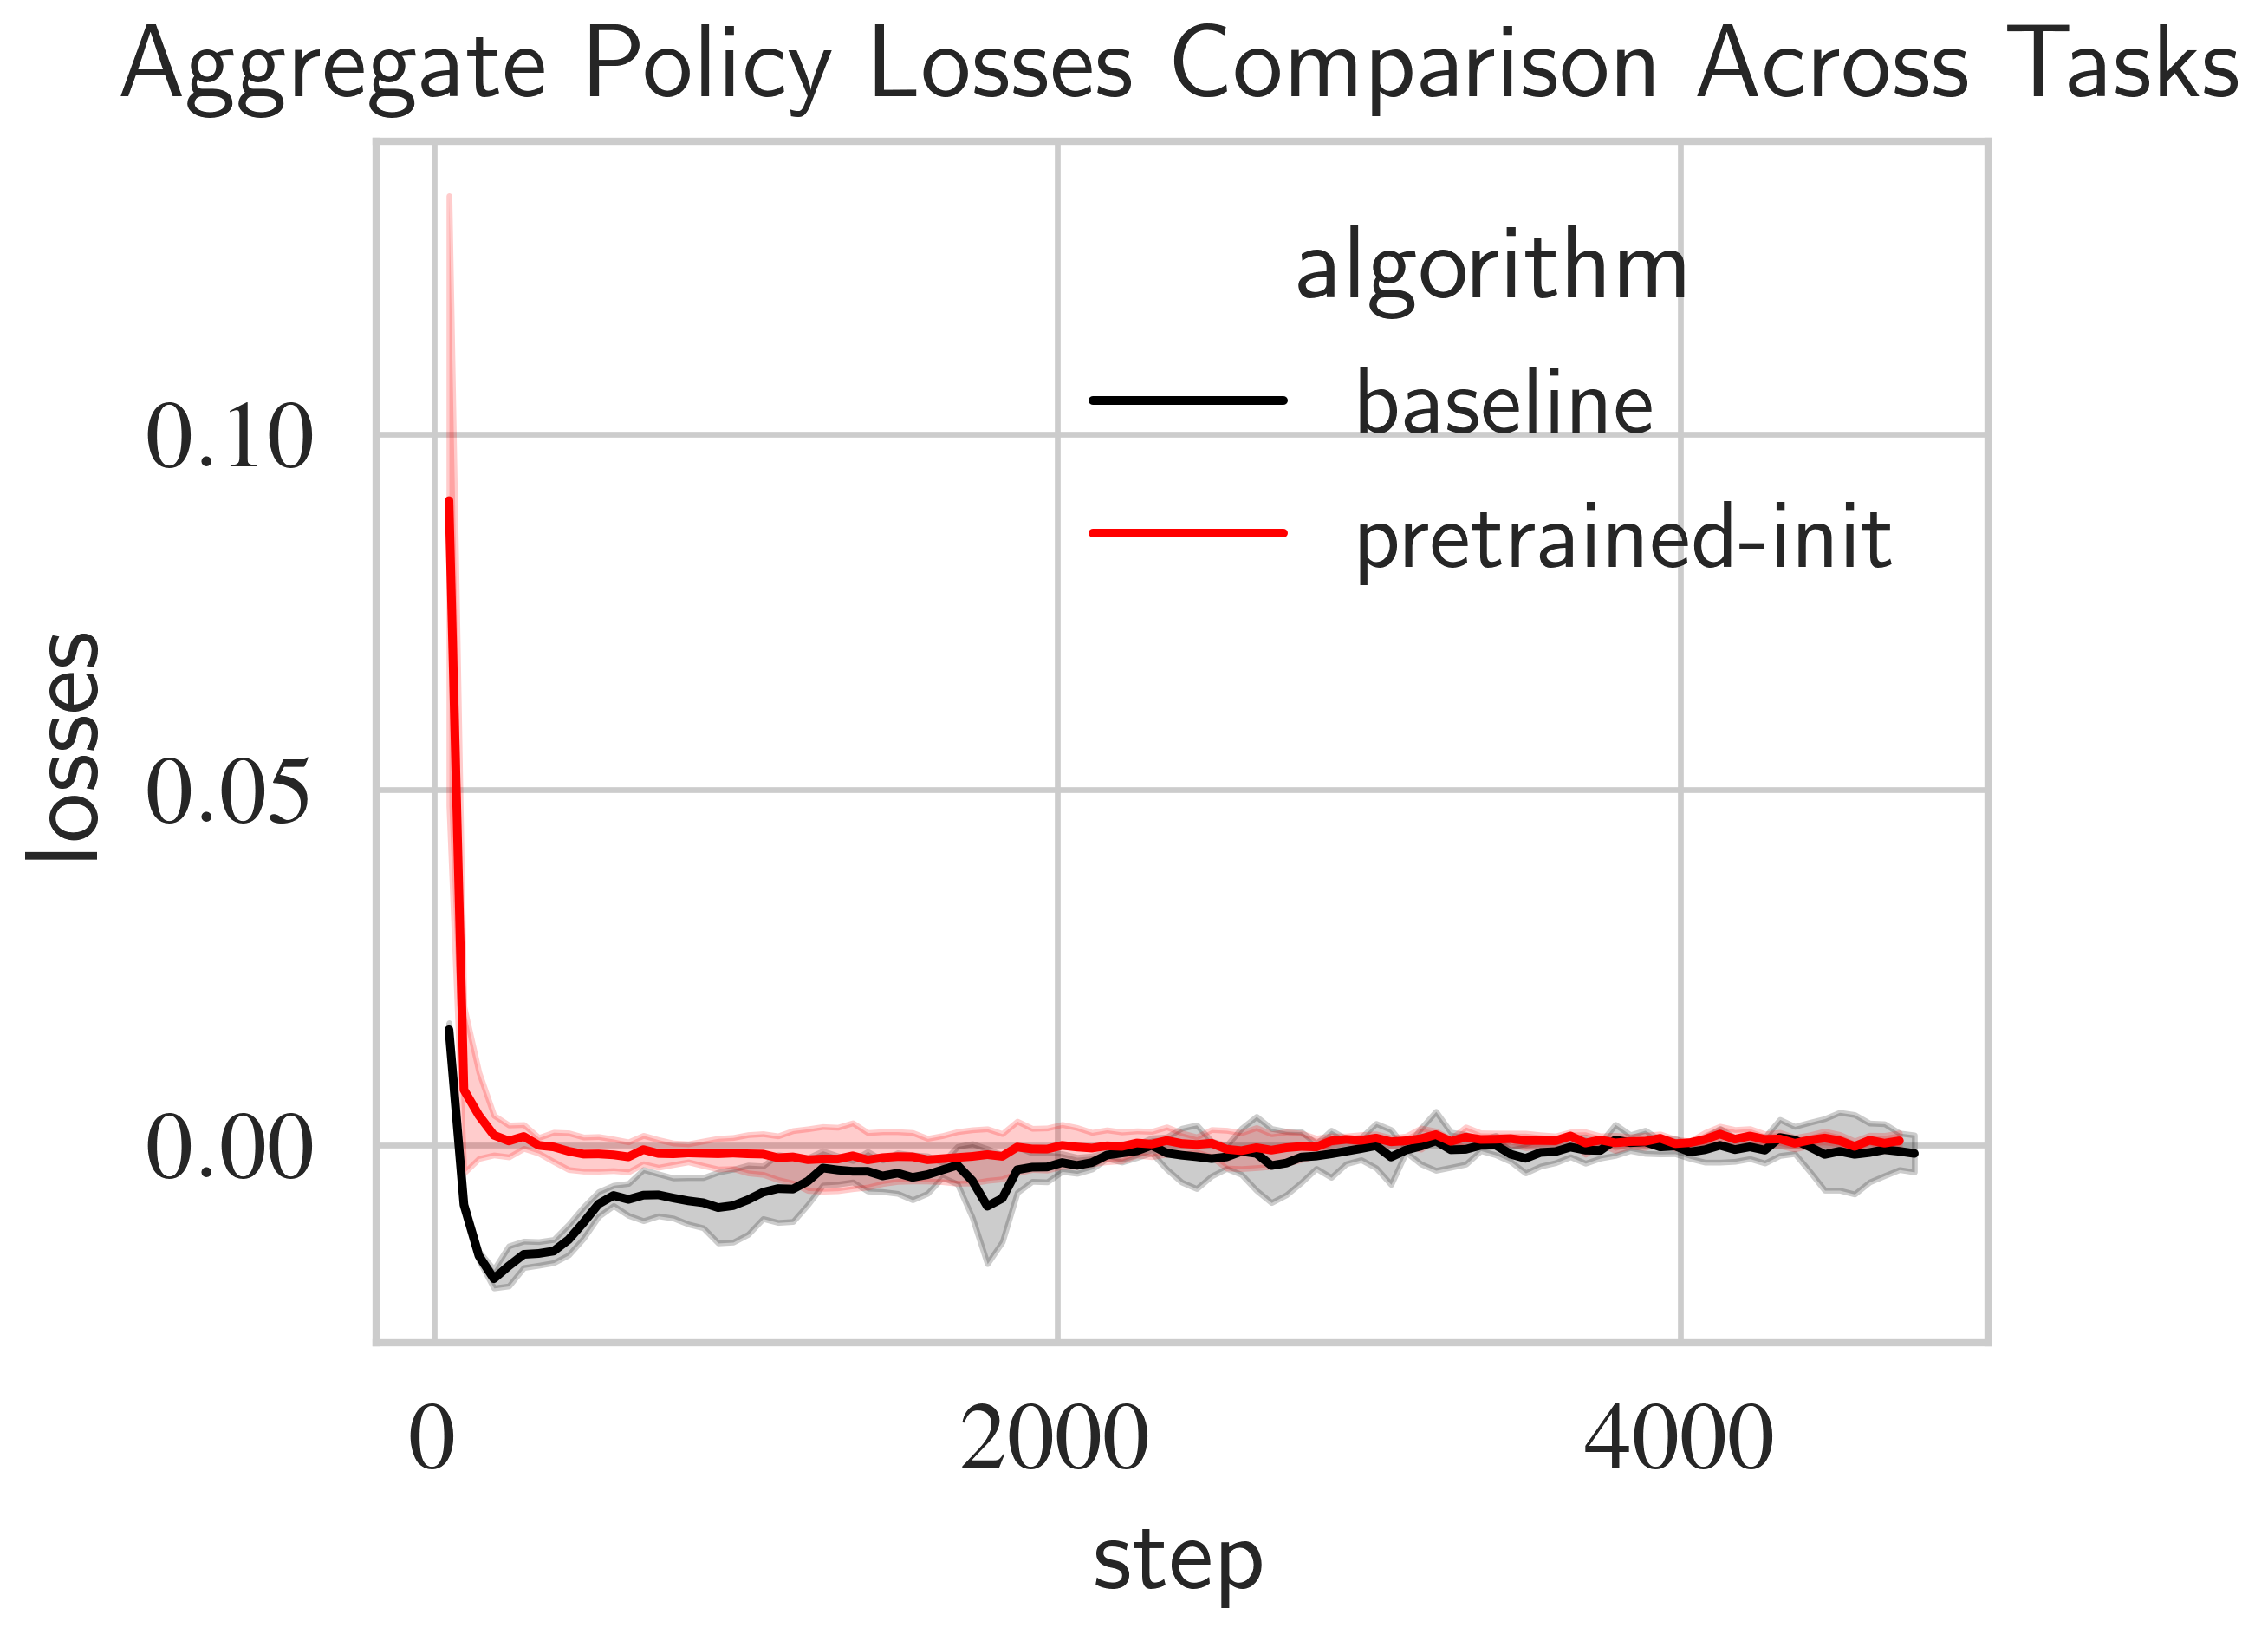

In [ ]:
plt.figure(figsize=(4,3))
ax = sns.lineplot(
    data=loss_summary,
    x="step", y="losses",
    hue="algorithm",
    # style="task",distance_to_goal
    errorbar="sd"
)
plt.title("Aggregate Policy Losses Comparison Across Tasks")
# plt.savefig("Policy-losses.pdf", dpi=300)

plt.savefig("Policy-losses.png", dpi=300)

In [ ]:
base_dir = 